<a href="https://colab.research.google.com/github/The-Harsh-07/RCA-CIE-Activity-AD3121/blob/main/Unit-1/RCA_CIE_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from statsmodels.stats.outliers_influence import variance_inflation_factor


In [ ]:
housing = fetch_california_housing(as_frame=True)
df = housing.frame.copy()
print("Shape (rows, cols):", df.shape)
display(df.head())

Shape (rows, cols): (20640, 9)


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


In [ ]:
print("\nData types:\n", df.dtypes)
print("\nMissing values per column:\n", df.isna().sum())
print("\nDuplicate rows count:", df.duplicated().sum())


Data types:
 MedInc         float64
HouseAge       float64
AveRooms       float64
AveBedrms      float64
Population     float64
AveOccup       float64
Latitude       float64
Longitude      float64
MedHouseVal    float64
dtype: object

Missing values per column:
 MedInc         0
HouseAge       0
AveRooms       0
AveBedrms      0
Population     0
AveOccup       0
Latitude       0
Longitude      0
MedHouseVal    0
dtype: int64

Duplicate rows count: 0


In [ ]:
summary = df.describe().T
summary["range"] = summary["max"] - summary["min"]
units = {
    "MedInc": "$10,000s",
    "HouseAge": "years",
    "AveRooms": "rooms/household",
    "AveBedrms": "bedrooms/household",
    "Population": "persons",
    "AveOccup": "persons/household",
    "Latitude": "degrees N",
    "Longitude": "degrees W",
    "MedHouseVal": "$100,000s",
}
summary["unit"] = summary.index.map(units)
print("\nSummary statistics with units and range:")
display(summary[["unit", "min", "max", "range", "mean", "std", "50%"]])


Summary statistics with units and range:


,unit,min,max,range,mean,std,50%
MedInc,"$10,000s",0.499900,15.000100,14.500200,3.870671,1.899822,3.534800
HouseAge,years,1.000000,52.000000,51.000000,28.639486,12.585558,29.000000
AveRooms,rooms/household,0.846154,141.909091,141.062937,5.429000,2.474173,5.229129
AveBedrms,bedrooms/household,0.333333,34.066667,33.733333,1.096675,0.473911,1.048780
Population,persons,3.000000,35682.000000,35679.000000,1425.476744,1132.462122,1166.000000
AveOccup,persons/household,0.692308,1243.333333,1242.641026,3.070655,10.386050,2.818116
Latitude,degrees N,32.540000,41.950000,9.410000,35.631861,2.135952,34.260000
Longitude,degrees W,-124.350000,-114.310000,10.040000,-119.569704,2.003532,-118.490000
MedHouseVal,"$100,000s",0.149990,5.000010,4.850020,2.068558,1.153956,1.797000


In [ ]:
df = df.drop_duplicates().reset_index(drop=True)
# Check for non-positive values in features that must be positive
for col in ["MedInc", "AveRooms", "AveBedrms", "Population", "AveOccup"]:
    invalid_count = (df[col] <= 0).sum()
    if invalid_count > 0:
        print(f"Found {invalid_count} non-positive values in {col}; replacing with column median.")
        med = df.loc[df[col] > 0, col].median()
        df.loc[df[col] <= 0, col] = med
for col in df.columns:
    if df[col].isna().sum() > 0:
        df[col] = df[col].fillna(df[col].median())

target_col = "MedHouseVal"
feature_cols = [c for c in df.columns if c != target_col]

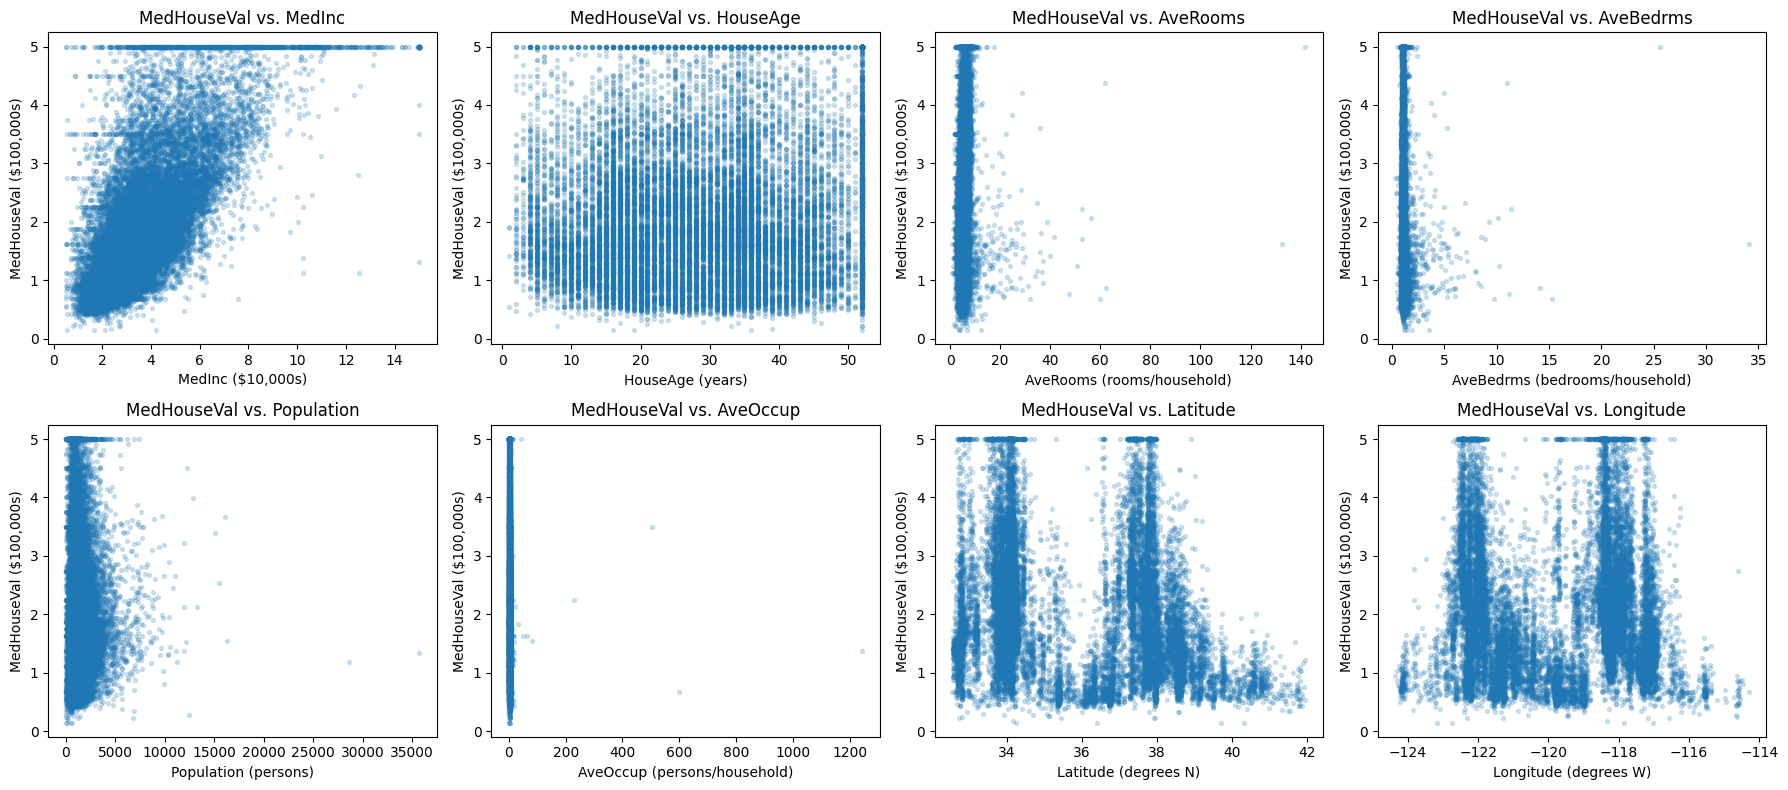

In [ ]:
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
axes = axes.flatten()
for i, col in enumerate(feature_cols):
    axes[i].scatter(df[col], df[target_col], alpha=0.2, s=8)
    axes[i].set_title(f"{target_col} vs. {col}")
    axes[i].set_xlabel(f"{col} ({units[col]})")
    axes[i].set_ylabel(f"{target_col} ({units[target_col]})")
plt.tight_layout()
plt.show()

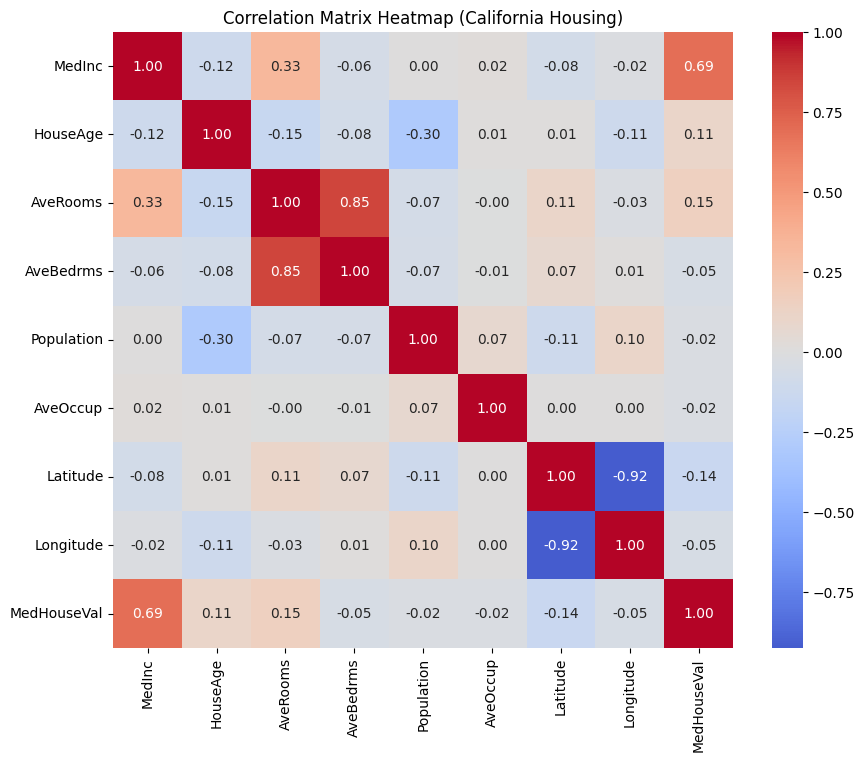


Feature correlations with target (MedHouseVal):
MedInc        0.688075
AveRooms      0.151948
HouseAge      0.105623
AveOccup     -0.023737
Population   -0.024650
Longitude    -0.045967
AveBedrms    -0.046701
Latitude     -0.144160
Name: MedHouseVal, dtype: float64

Strongest inter-feature correlations (|r| >= 0.5):
  AveRooms <-> AveBedrms: r = 0.848
  Latitude <-> Longitude: r = -0.925


In [ ]:
corr_matrix = df.corr()
plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation Matrix Heatmap (California Housing)")
plt.show()

print("\nFeature correlations with target (MedHouseVal):")
print(corr_matrix[target_col].drop(target_col).sort_values(ascending=False))

print("\nStrongest inter-feature correlations (|r| >= 0.5):")
feat_corr = df[feature_cols].corr()
for i in range(len(feature_cols)):
    for j in range(i + 1, len(feature_cols)):
        r_val = feat_corr.iloc[i, j]
        if abs(r_val) >= 0.5:
            print(f"  {feature_cols[i]} <-> {feature_cols[j]}: r = {r_val:.3f}")

In [ ]:
X = df[feature_cols]
y = df[target_col]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(f"\nTrain rows: {len(X_train)}, Test rows: {len(X_test)}")


Train rows: 16512, Test rows: 4128


In [ ]:
scaler = StandardScaler()
X_train_scaled = pd.DataFrame(scaler.fit_transform(X_train), columns=feature_cols, index=X_train.index)
X_test_scaled = pd.DataFrame(scaler.transform(X_test), columns=feature_cols, index=X_test.index)

In [ ]:
top_feature = corr_matrix[target_col].drop(target_col).abs().idxmax()
single_model = LinearRegression()
single_model.fit(X_train[[top_feature]], y_train)
y_test_pred_single = single_model.predict(X_test[[top_feature]])
r2_single_test = r2_score(y_test, y_test_pred_single)

print(f"\nSingle-feature model ({top_feature}):")
print(f"  Intercept: {single_model.intercept_:.4f}")
print(f"  Coef ({top_feature}): {single_model.coef_[0]:.4f}")
print(f"  Test R^2: {r2_single_test:.4f}")


Single-feature model (MedInc):
  Intercept: 0.4446
  Coef (MedInc): 0.4193
  Test R^2: 0.4589


In [ ]:
multi_model = LinearRegression()
multi_model.fit(X_train, y_train)
print(f"\nMultiple model intercept: {multi_model.intercept_:.4f}")
coef_df = pd.DataFrame({
    "feature": feature_cols,
    "raw_coef": multi_model.coef_,
    "unit_effect_on_y": [f"{c:+.4f} ($100k) per +1 {units[f]}" for f, c in zip(feature_cols, multi_model.coef_)]
})


Multiple model intercept: -37.0233


In [ ]:
multi_scaled_model = LinearRegression().fit(X_train_scaled, y_train)
coef_df["std_coef (per +1 SD)"] = multi_scaled_model.coef_
display(coef_df)

,feature,raw_coef,unit_effect_on_y,std_coef (per +1 SD)
0,MedInc,0.448675,"+0.4487 ($100k) per +1 $10,000s",0.854383
1,HouseAge,0.009724,+0.0097 ($100k) per +1 years,0.122546
2,AveRooms,-0.123323,-0.1233 ($100k) per +1 rooms/household,-0.294410
3,AveBedrms,0.783145,+0.7831 ($100k) per +1 bedrooms/household,0.339259
4,Population,-0.000002,-0.0000 ($100k) per +1 persons,-0.002308
5,AveOccup,-0.003526,-0.0035 ($100k) per +1 persons/household,-0.040829
6,Latitude,-0.419792,-0.4198 ($100k) per +1 degrees N,-0.896929
7,Longitude,-0.433708,-0.4337 ($100k) per +1 degrees W,-0.869842


In [ ]:
X_sample = np.array([[1, 2], [2, 1], [3, 3], [4, 2], [5, 4], [6, 3]])
y_sample = np.array([7, 9, 14, 16, 21, 23])
sample_model = LinearRegression().fit(X_sample, y_sample)
print("\nStep 4 Verification via scikit-learn:")
print("  b0 (intercept):", round(sample_model.intercept_, 6))
print("  b1, b2 (coefs):", np.round(sample_model.coef_, 6))
print("  Difference vs hand calc (2, [3, 1]):",
      abs(sample_model.intercept_ - 2.0), np.abs(sample_model.coef_ - np.array([3.0, 1.0])))


Step 4 Verification via scikit-learn:
  b0 (intercept): 2.0
  b1, b2 (coefs): [3. 1.]
  Difference vs hand calc (2, [3, 1]): 1.7763568394002505e-15 [0.00000000e+00 6.66133815e-16]


In [ ]:
terms = [f"({c:+.4f})*{f}" for f, c in zip(feature_cols, multi_model.coef_)]
print(f"\nFitted equation: MedHouseVal = {multi_model.intercept_:.4f} " + " ".join(terms))


Fitted equation: MedHouseVal = -37.0233 (+0.4487)*MedInc (+0.0097)*HouseAge (-0.1233)*AveRooms (+0.7831)*AveBedrms (-0.0000)*Population (-0.0035)*AveOccup (-0.4198)*Latitude (-0.4337)*Longitude


In [ ]:
y_test_pred_multi = multi_model.predict(X_test)
pred_comparison = pd.DataFrame({
    "Actual_MedHouseVal": y_test.values,
    "Predicted_MedHouseVal": y_test_pred_multi,
    "Error (Actual - Pred)": y_test.values - y_test_pred_multi
})
print("\nSample of 15 test set predictions vs actuals:")
display(pred_comparison.head(15))


Sample of 15 test set predictions vs actuals:


,Actual_MedHouseVal,Predicted_MedHouseVal,Error (Actual - Pred)
0,0.47700,0.719123,-0.242123
1,0.45800,1.764017,-1.306017
2,5.00001,2.709659,2.290351
3,2.18600,2.838926,-0.652926
4,2.78000,2.604657,0.175343
5,1.58700,2.011754,-0.424754
6,1.98200,2.645500,-0.663500
7,1.57500,2.168755,-0.593755
8,3.40000,2.740746,0.659254
9,4.46600,3.915615,0.550385


In [ ]:
def adjusted_r2(r2, n, p):
    return 1 - (1 - r2) * (n - 1) / (n - p - 1)

n_test = len(y_test)
mae_single = mean_absolute_error(y_test, y_test_pred_single)
mse_single = mean_squared_error(y_test, y_test_pred_single)
rmse_single = np.sqrt(mse_single)
adj_r2_single = adjusted_r2(r2_single_test, n_test, 1)

r2_multi_test = r2_score(y_test, y_test_pred_multi)
mae_multi = mean_absolute_error(y_test, y_test_pred_multi)
mse_multi = mean_squared_error(y_test, y_test_pred_multi)
rmse_multi = np.sqrt(mse_multi)
adj_r2_multi = adjusted_r2(r2_multi_test, n_test, len(feature_cols))

eval_df = pd.DataFrame({
    "Metric": ["MAE ($100k)", "MSE ($100k^2)", "RMSE ($100k)", "Test R^2", "Adjusted R^2"],
    f"Single-Feature ({top_feature})": [mae_single, mse_single, rmse_single, r2_single_test, adj_r2_single],
    "Multiple-Feature (All 8)": [mae_multi, mse_multi, rmse_multi, r2_multi_test, adj_r2_multi],
})
print("\nTest Set Evaluation Comparison:")
display(eval_df)


Test Set Evaluation Comparison:


,Metric,Single-Feature (MedInc),Multiple-Feature (All 8)
0,MAE ($100k),0.629909,0.533200
1,MSE ($100k^2),0.709116,0.555892
2,RMSE ($100k),0.842090,0.745581
3,Test R^2,0.458859,0.575788
4,Adjusted R^2,0.458728,0.574964


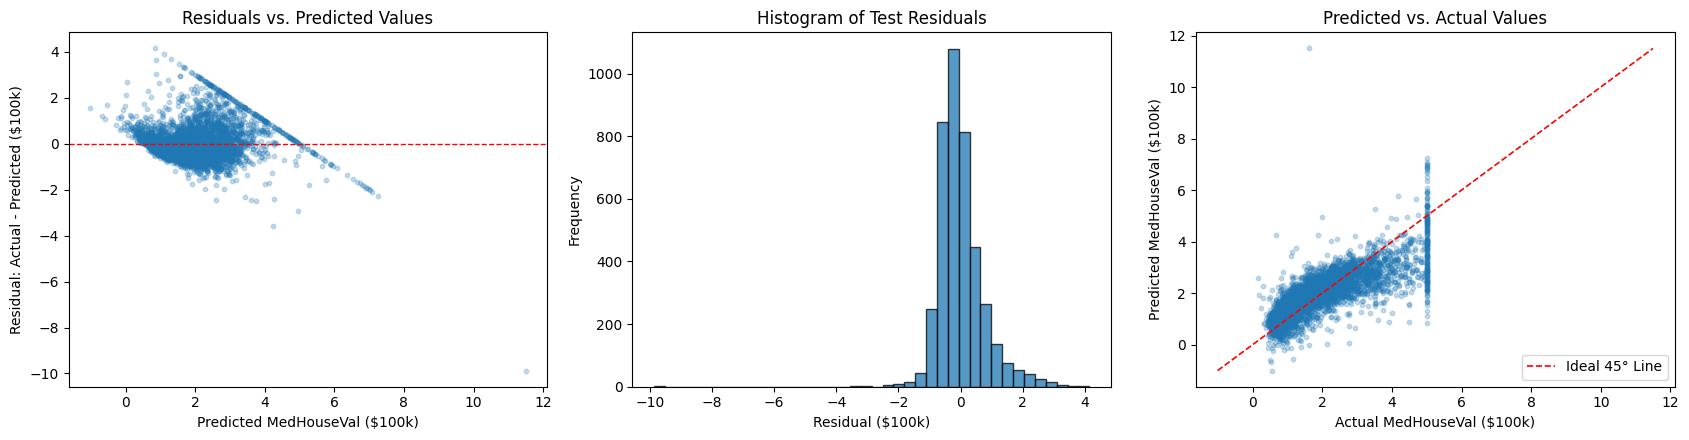

In [ ]:
residuals = y_test.values - y_test_pred_multi
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
axes[0].scatter(y_test_pred_multi, residuals, alpha=0.25, s=10)
axes[0].axhline(0, color="red", linestyle="--", linewidth=1)
axes[0].set_title("Residuals vs. Predicted Values")
axes[0].set_xlabel("Predicted MedHouseVal ($100k)")
axes[0].set_ylabel("Residual: Actual - Predicted ($100k)")

axes[1].hist(residuals, bins=40, edgecolor="black", alpha=0.75)
axes[1].set_title("Histogram of Test Residuals")
axes[1].set_xlabel("Residual ($100k)")
axes[1].set_ylabel("Frequency")

axes[2].scatter(y_test.values, y_test_pred_multi, alpha=0.25, s=10)
min_val = min(y_test.min(), y_test_pred_multi.min())
max_val = max(y_test.max(), y_test_pred_multi.max())
axes[2].plot([min_val, max_val], [min_val, max_val], "r--", linewidth=1.2, label="Ideal 45° Line")
axes[2].set_title("Predicted vs. Actual Values")
axes[2].set_xlabel("Actual MedHouseVal ($100k)")
axes[2].set_ylabel("Predicted MedHouseVal ($100k)")
axes[2].legend()

plt.tight_layout()
plt.show()

In [ ]:
X_train_with_const = X_train.assign(const=1.0)
vif_df = pd.DataFrame({
    "feature": feature_cols,
    "VIF": [
        variance_inflation_factor(X_train_with_const.values, i)
        for i in range(len(feature_cols))
    ]
})
print("\nVariance Inflation Factor (VIF):")
display(vif_df.sort_values("VIF", ascending=False))


Variance Inflation Factor (VIF):


,feature,VIF
6,Latitude,9.206134
7,Longitude,8.875984
2,AveRooms,7.917240
3,AveBedrms,6.609200
0,MedInc,2.539815
1,HouseAge,1.237337
4,Population,1.134824
5,AveOccup,1.009733


In [ ]:
new_record = pd.DataFrame([{
    "MedInc": 5.2,
    "HouseAge": 25.0,
    "AveRooms": 5.5,
    "AveBedrms": 1.1,
    "Population": 1200.0,
    "AveOccup": 2.8,
    "Latitude": 34.05,
    "Longitude": -118.25,
}])
new_pred = multi_model.predict(new_record)[0]
print(f"\nNew example predicted MedHouseVal: {new_pred:.3f} ($100,000s) -> approx. ${new_pred * 100_000:,.0f}")


New example predicted MedHouseVal: 2.716 ($100,000s) -> approx. $271,585
